# 02 - Thực nghiệm so sánh các mô hình

Chạy đầy đủ pipeline thống nhất với `main.py`, sau đó nạp bảng metric để xem kết quả. Chia dữ liệu mặc định stratified 80/20, seed 42. Các chỉ số là kết quả của lần chia này, không phải xác nhận lâm sàng hay bảo đảm mô hình tổng quát hóa.

In [1]:
from pathlib import Path
import subprocess
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "main.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
command = [sys.executable, str(PROJECT_ROOT / "main.py")]
subprocess.run(command, cwd=PROJECT_ROOT, check=True)

CompletedProcess(args=['d:\\TDTU\\NĂM 3\\HK I\\ML GK\\repo\\Ensemble-learning\\.venv\\Scripts\\python.exe', 'd:\\TDTU\\NĂM 3\\HK I\\ML GK\\repo\\Ensemble-learning\\main.py'], returncode=0)

## Bảng metric trên test

Positive class là malignant (M). Với sàng lọc, cần đặc biệt xem Recall cùng với Precision; không nên chỉ xếp hạng bằng Accuracy.

,model,accuracy,precision,recall,f1,roc_auc,fit_seconds
0,Stacking,0.9912,1.0000,0.9762,0.9880,0.9964,2.2534
1,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9954,0.0096
2,SVM (RBF),0.9737,0.9756,0.9524,0.9639,0.9940,0.0531
3,Random Forest,0.9737,1.0000,0.9286,0.9630,0.9980,0.3528
4,Soft Voting,0.9737,1.0000,0.9286,0.9630,0.9967,0.3737
5,AdaBoost,0.9737,1.0000,0.9286,0.9630,0.9858,0.1811
6,Hard Voting (from scratch),0.9737,1.0000,0.9286,0.9630,0.9643,0.0001
7,Gradient Boosting,0.9649,1.0000,0.9048,0.9500,0.9940,0.1722
8,k-NN,0.9561,0.9744,0.9048,0.9383,0.9823,0.0036
9,Decision Tree,0.9035,0.9189,0.8095,0.8608,0.8342,0.0083


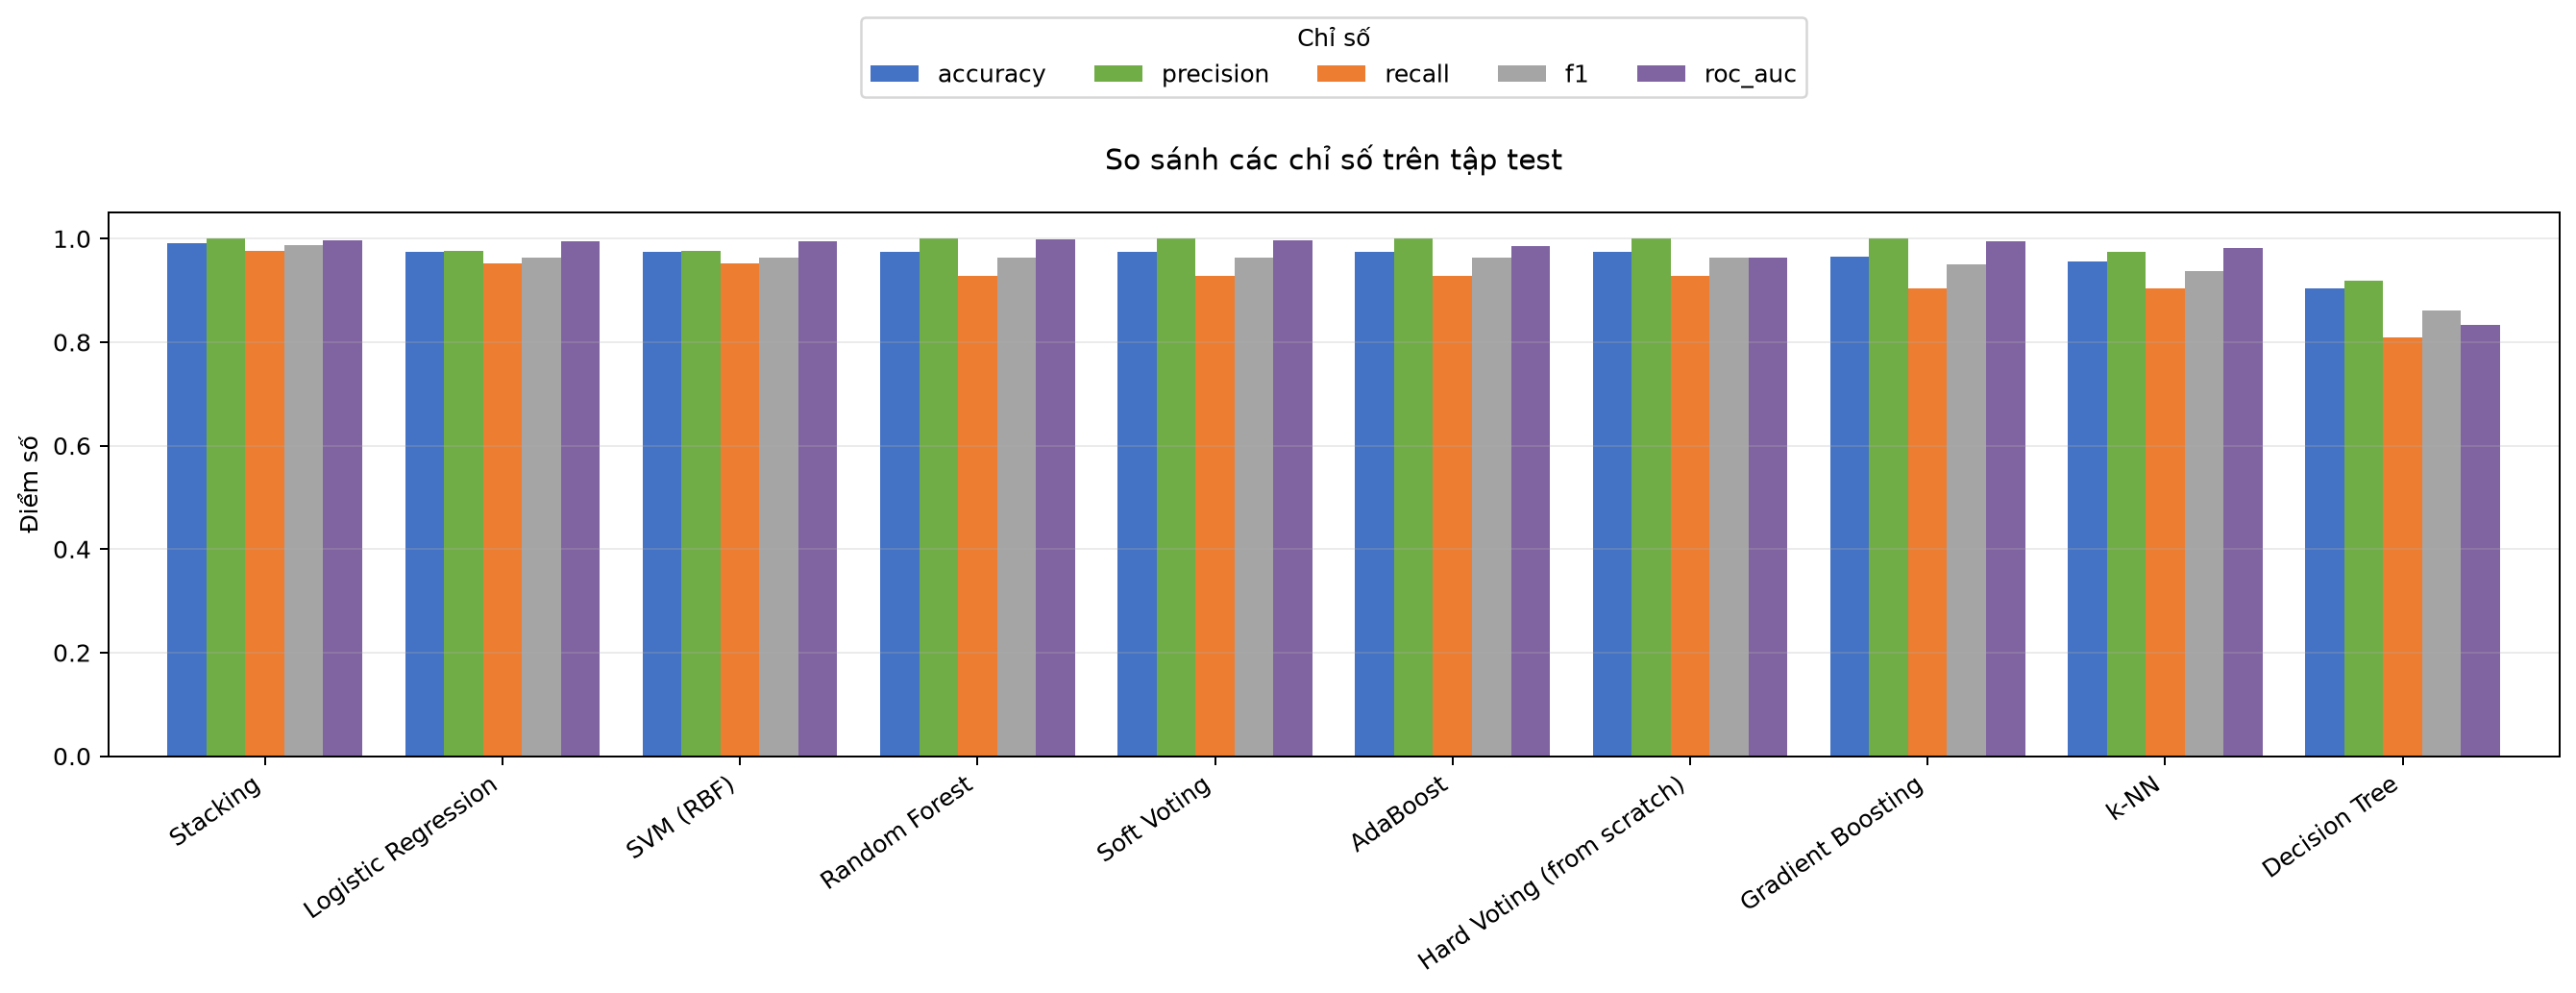

In [2]:
import pandas as pd
from IPython.display import display, Image

results_dir = PROJECT_ROOT / "results"
metrics = pd.read_csv(results_dir / "metrics.csv")
display(metrics.round(4))
display(Image(filename=str(results_dir / "figures" / "model_comparison.png")))

## ROC và confusion matrix

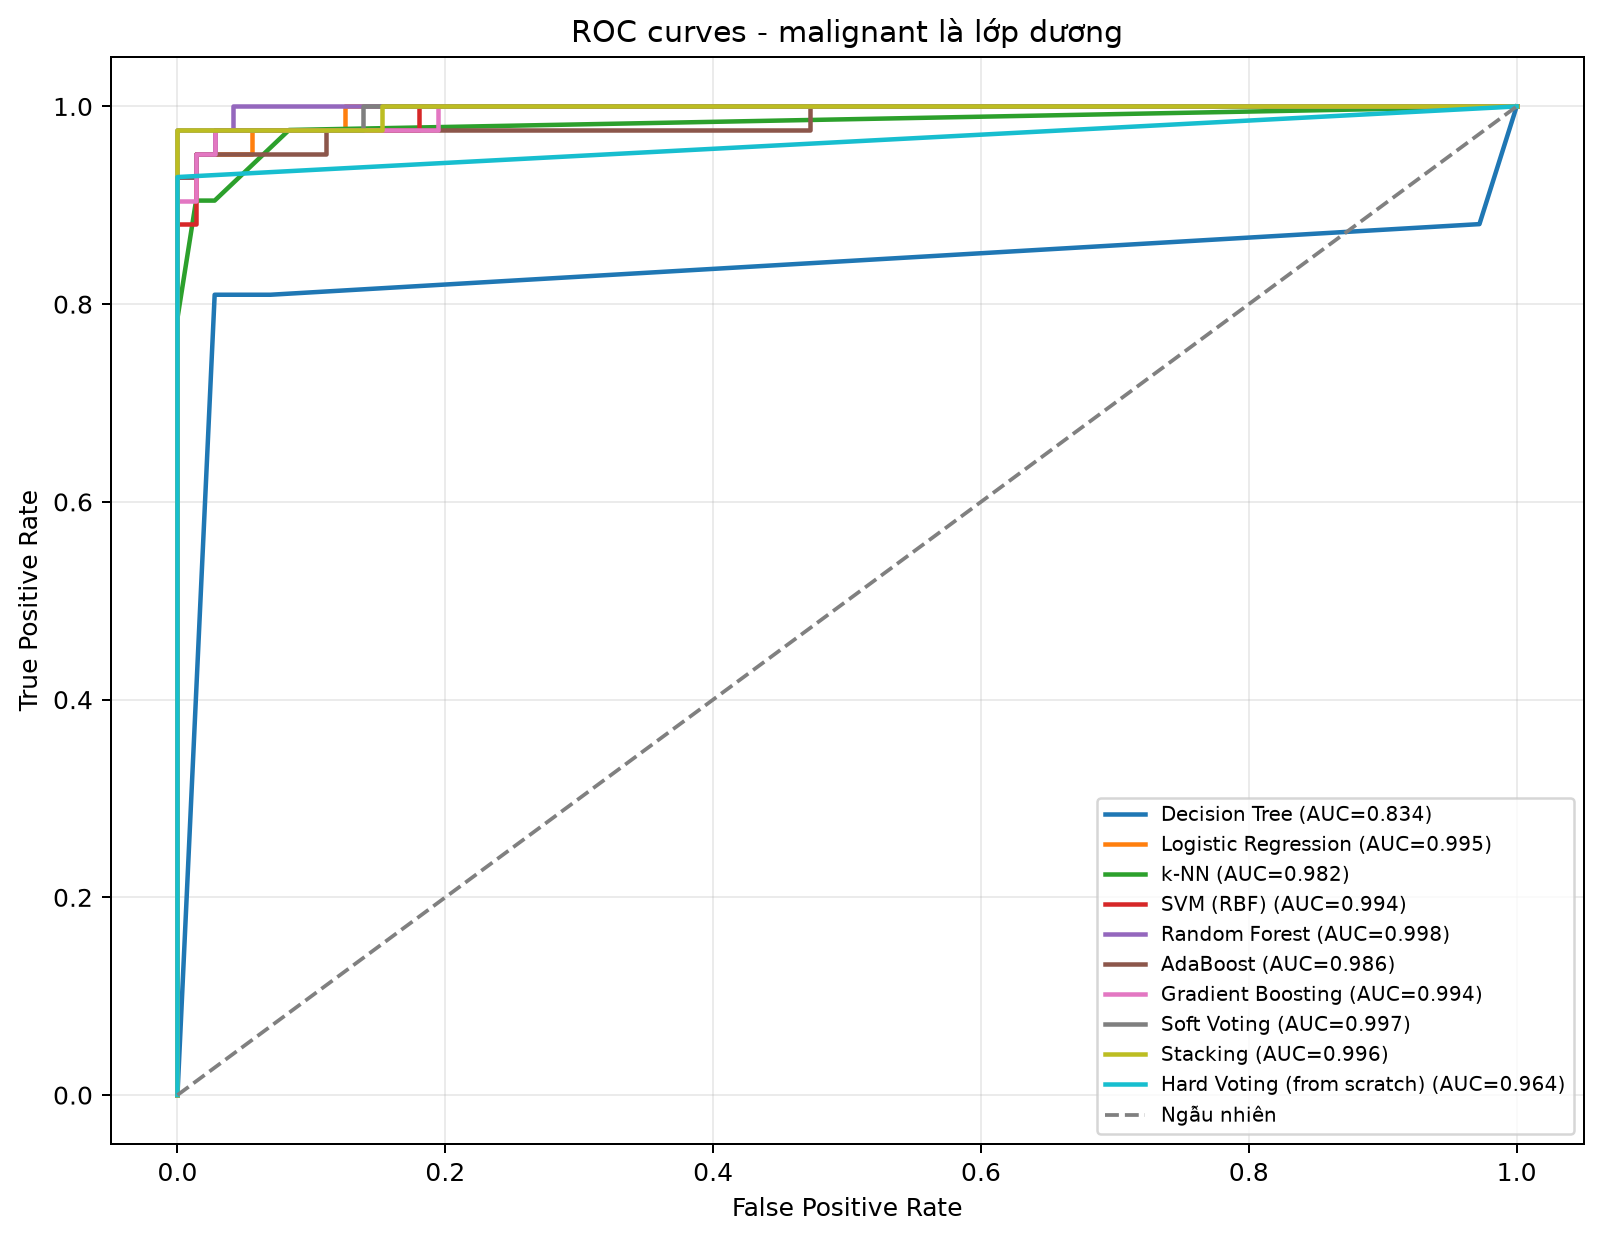

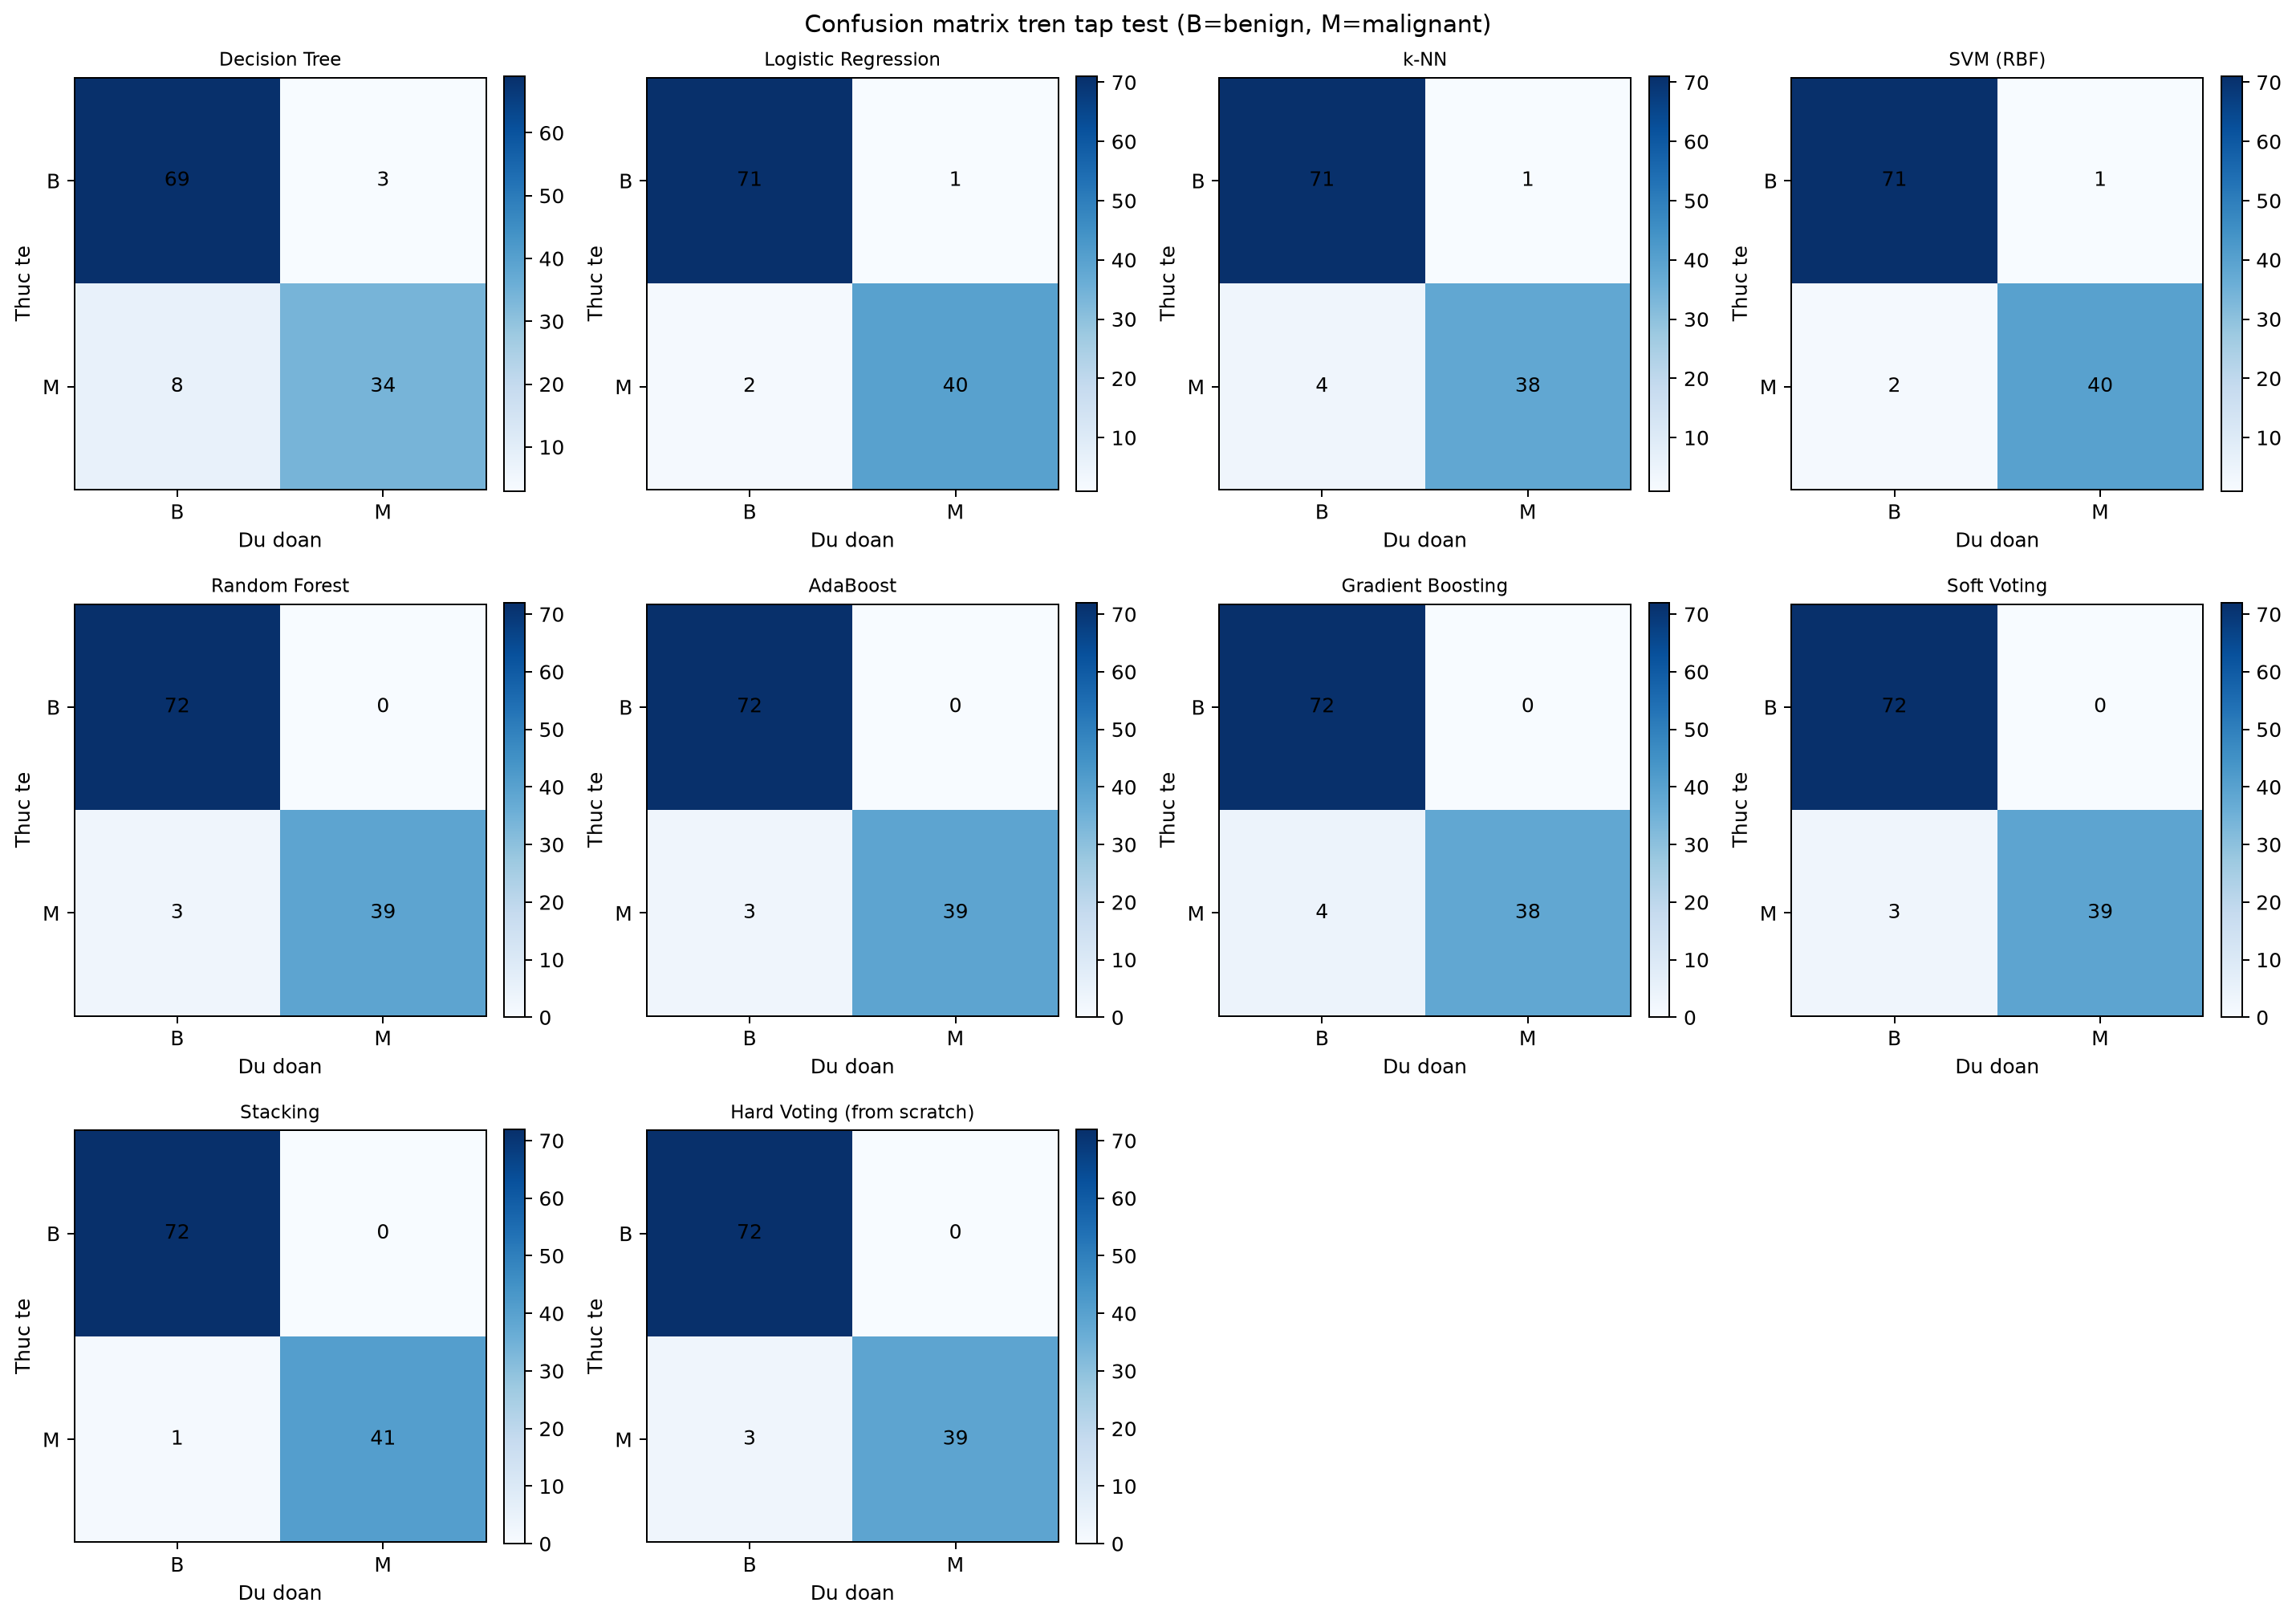

In [3]:
display(Image(filename=str(results_dir / "figures" / "roc_curves.png")))
display(Image(filename=str(results_dir / "figures" / "confusion_matrices.png")))

## Feature importance và phân tích lỗi

Feature importance của cây phản ánh mức độ sử dụng đặc trưng trong quá trình chia nhánh, không phải quan hệ nhân quả. Danh sách lỗi của Random Forest giúp xem các ID bị dự đoán sai; không nên suy diễn chẩn đoán từ kết quả này.

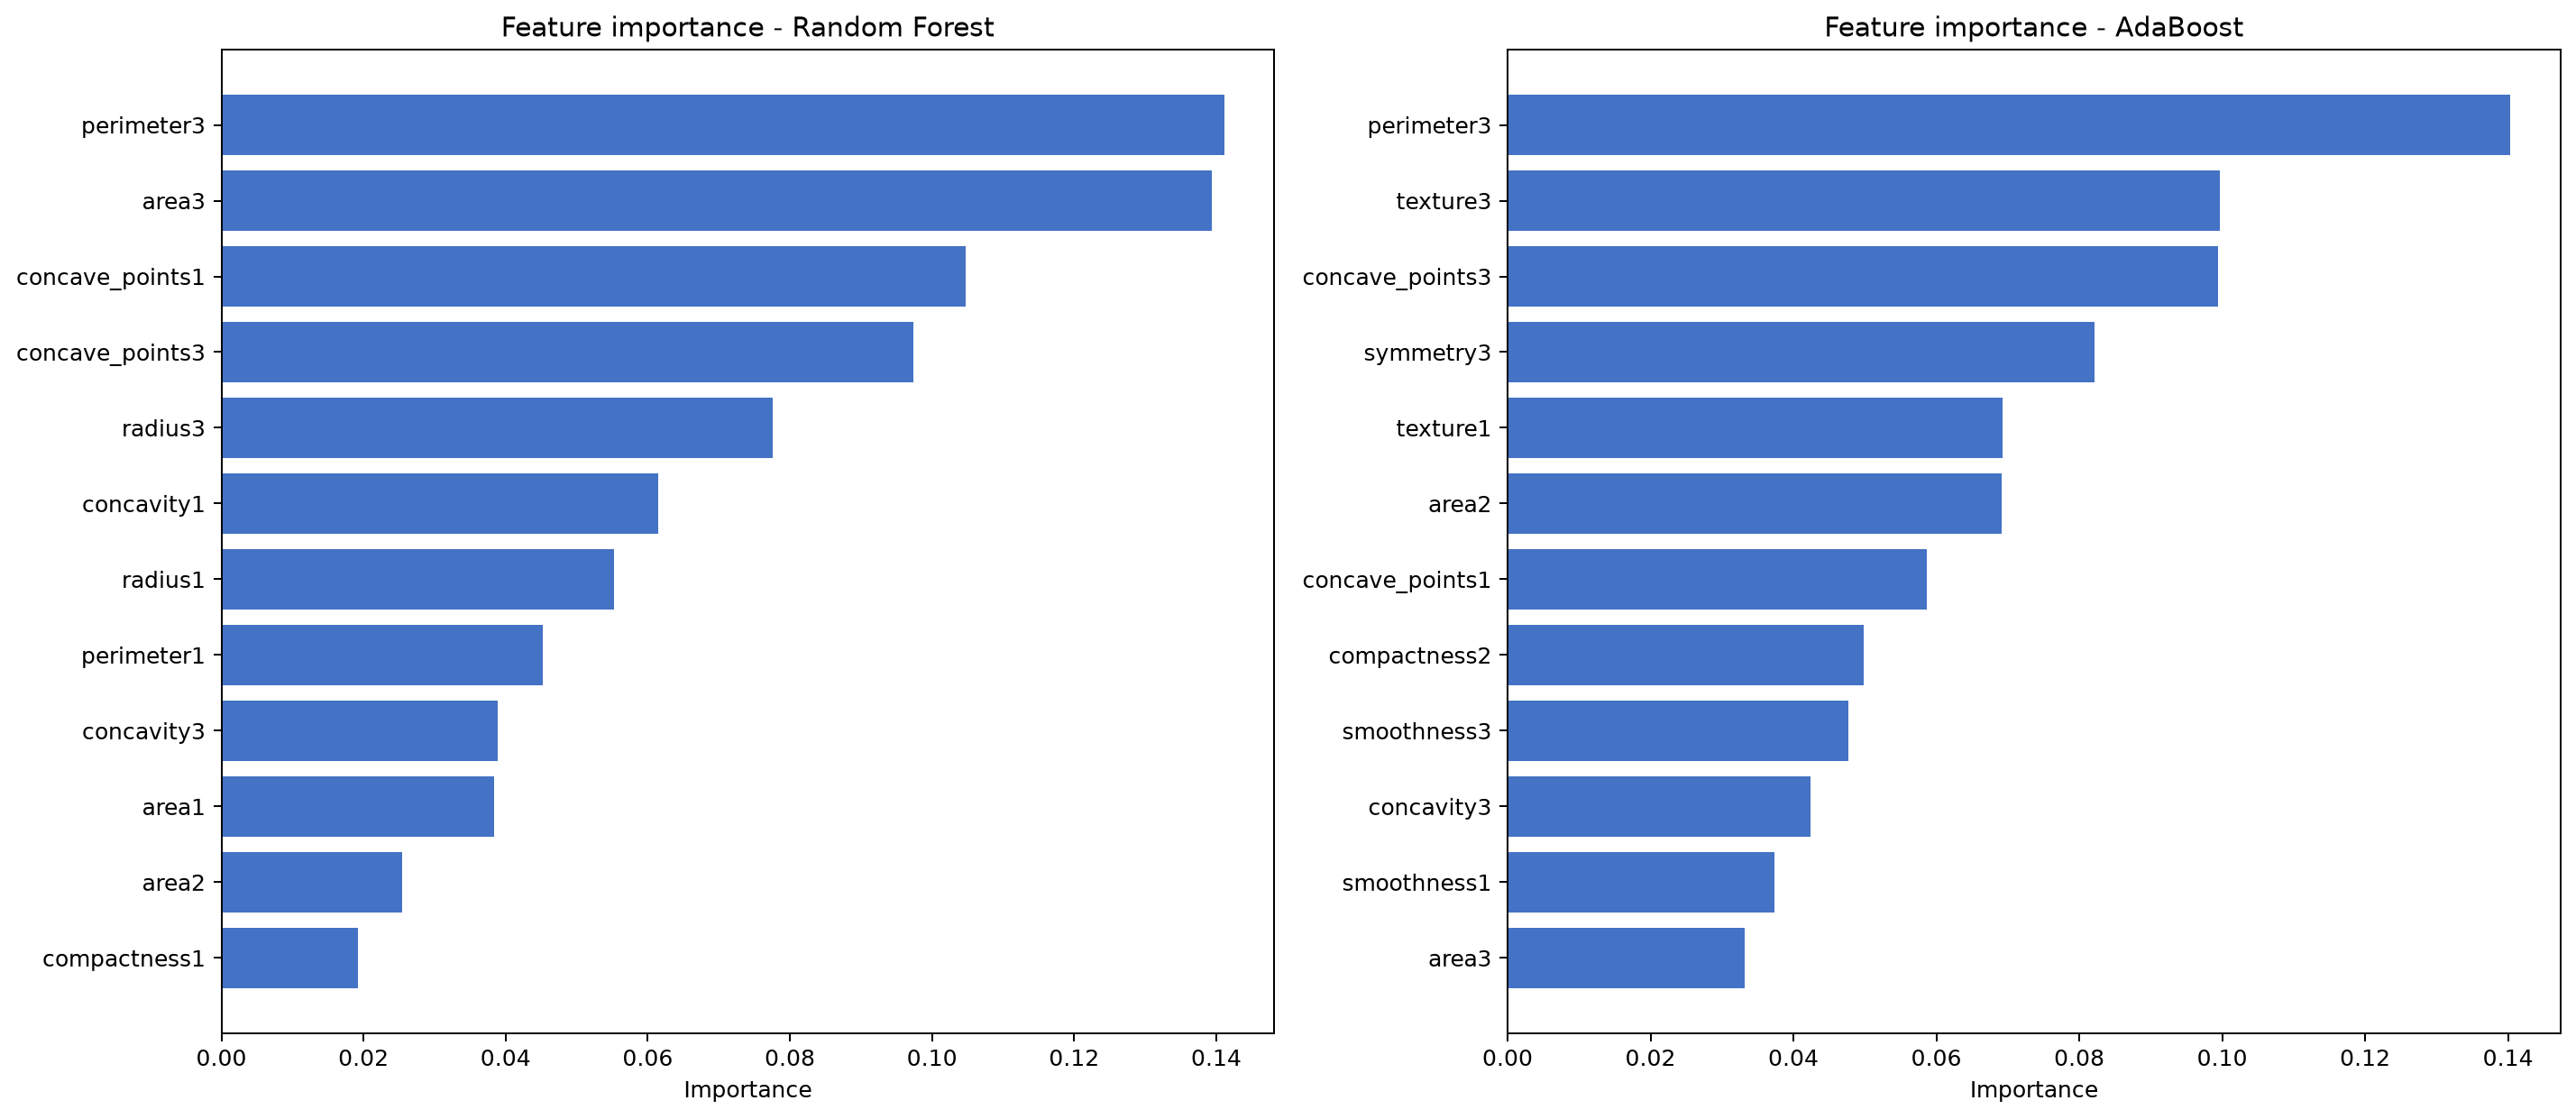

Random Forest dự đoán sai 3 mẫu trên test.


,ID,actual,predicted
0,859983,M,B
1,86135501,M,B
2,90291,M,B


# Nhận xét thực nghiệm

Các chỉ số dưới đây được tính trên một tập test phân tầng 20%;
đây là kết quả của một lần chia dữ liệu, không phải ước lượng tổng quát hóa.

- Mô hình có F1 cao nhất trong lần chạy này: **Stacking** (F1=0.988, Recall=0.976, ROC-AUC=0.996).
- Base model tốt nhất theo F1: **Logistic Regression** (F1=0.964); chênh lệch F1 giữa hai mô hình là +0.024. Kết quả này không khẳng định ensemble luôn tốt hơn.
- Với bài toán sàng lọc, Recall của lớp malignant cần được xem xét cùng Precision vì bỏ sót ca malignant có chi phí cao; ROC-AUC đánh giá khả năng xếp hạng ở nhiều ngưỡng.
- Random Forest dự đoán sai 3 mẫu trên test, gồm 3 false negative (M bị đoán thành B) và 0 false positive (B bị đoán thành M). Xem `results/misclassified_random_forest.csv` để kiểm tra từng trường hợp.
- Feature importance của cây là mức đóng góp theo tiêu chí chia trong các cây, không chứng minh quan hệ nhân quả và có thể thiên lệch với các đặc trưng tương quan.
- Ensemble thường giảm phương sai (Ra

In [4]:
display(Image(filename=str(results_dir / "figures" / "feature_importance.png")))
errors = pd.read_csv(results_dir / "misclassified_random_forest.csv")
print(f"Random Forest dự đoán sai {len(errors)} mẫu trên test.")
display(errors.head(10))
print((results_dir / "experiment_notes.md").read_text(encoding="utf-8"))